# 01 – Cadrage et analyse des données

Projet : prédire les défauts de paiement sur carte de crédit.
Données : Default of Credit Card Clients (UCI, id 350), Yeh (2009), licence CC BY 4.0. La source et la date de téléchargement sont dans `data/SOURCE.md`.

Ce notebook couvre les axes 1 (cadrage), 2 (type de problème) et 3 (analyse des données).

## 1. Cadrage (axe 1)

| | |
|---|---|
| Contexte | Une banque qui émet des cartes de crédit. Les données viennent d'une banque taïwanaise : 30 000 clients, relevés d'avril à septembre 2005. Le résultat est destiné au service recouvrement. |
| Problème | Environ 22 % des clients ne paient pas leur facture le mois suivant. |
| Décision | Chaque mois, choisir quels clients appeler avant l'échéance (rappel, proposition d'échéancier). |
| Horizon | 1 mois. J'utilise ce qui est connu fin septembre pour prédire le défaut du mois suivant. |
| Situation actuelle | Je suppose que la banque appelle les clients déjà en retard sur le dernier relevé (`retard_sep >= 1`). C'est ma référence, chiffrée en partie 6. |
| Critère de succès | Avec le même nombre d'appels que la règle actuelle (environ 23 % des clients), couvrir au moins 70 % des montants en défaut, contre 55 % aujourd'hui. Vérifié sur le jeu de test, puis sur un pilote de 3 mois. |
| Contraintes | Utiliser seulement les données connues au moment de la décision. Pouvoir expliquer au conseiller pourquoi il appelle un client. Ne pas utiliser le sexe, l'âge et la situation familiale. |

## 2. Type de problème (axe 2)

La cible est `defaut` : 1 si le client est en défaut de paiement le mois suivant, 0 sinon. Elle est connue pour tous les clients, donc c'est un problème supervisé. Comme elle n'a que deux valeurs, c'est une classification binaire.

Pourquoi pas autre chose :
- une régression n'a pas de sens ici, on ne connaît pas le montant du défaut ;
- un clustering n'utiliserait pas la cible alors qu'on l'a ;
- ce n'est pas une série temporelle : tous les clients sont observés à la même date, les 6 mois d'historique sont juste des variables.

Le modèle donnera une probabilité de défaut. Pour décider qui appeler, je la multiplierai par le montant de la facture (perte attendue), pour appeler en priorité les clients qui représentent le plus gros risque.

In [1]:
import sys #pour les reglages , le chargement et l'import des données tout en renommant les colonnes

sys.path.append("..")          

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from src.donnees import charger_donnees, regrouper_codes, ajouter_variables, RETARDS, FACTURES, PAIEMENTS

sns.set_theme(style="whitegrid")

FIGURES = "../reports/figures/"   

df = charger_donnees()             

print("Dimensions :", df.shape)

df.head()

Dimensions : (30000, 25)


,id_client,plafond_credit,sexe,education,statut_marital,age,retard_sep,retard_aou,retard_jul,retard_jun,...,facture_jun,facture_mai,facture_avr,paiement_sep,paiement_aou,paiement_jul,paiement_jun,paiement_mai,paiement_avr,defaut
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Dictionnaire des variables

Les montants sont en dollars taïwanais (TWD). Les mois vont d'avril à septembre 2005.

| Variable | Nom d'origine | Type | Description |
|---|---|---|---|
| `id_client` | ID | identifiant | numéro du client |
| `plafond_credit` | X1 | numérique (TWD) | plafond de la carte, cartes supplémentaires du foyer comprises |
| `sexe` | X2 | catégorielle | 1 = homme, 2 = femme |
| `education` | X3 | catégorielle | 1 = master/doctorat, 2 = université, 3 = lycée, 4 = autre |
| `statut_marital` | X4 | catégorielle | 1 = marié, 2 = célibataire, 3 = autre |
| `age` | X5 | numérique (années) | âge du client |
| `retard_sep` à `retard_avr` | X6 à X11 | ordinale | statut de paiement du mois : -1 = payé à temps, 1 à 9 = nombre de mois de retard |
| `facture_sep` à `facture_avr` | X12 à X17 | numérique (TWD) | montant du relevé du mois |
| `paiement_sep` à `paiement_avr` | X18 à X23 | numérique (TWD) | montant payé dans le mois |
| `defaut` | Y | binaire | cible : 1 = défaut le mois suivant |

## 4. Qualité des données (axe 3)

### 4.1 Valeurs manquantes et doublons

In [2]:
print("Types de colonnes :", df.dtypes.value_counts().to_dict())

#pour verifier la qualité et les types et valeurs mansquantes ou en doublons dans la data

print("Valeurs manquantes :", df.isna().sum().sum())

print("Identifiants en double :", df["id_client"].duplicated().sum())

sans_id = df.drop(columns="id_client")

print("Lignes identiques (sans l'identifiant) :", sans_id.duplicated().sum())

doublons = sans_id[sans_id.duplicated(keep=False)]

print("Lignes concernées :", len(doublons), "dont", (doublons[FACTURES] == 0).all(axis=1).sum(), "sans aucune facture")

Types de colonnes : {dtype('int64'): 25}
Valeurs manquantes : 0
Identifiants en double : 0
Lignes identiques (sans l'identifiant) : 35
Lignes concernées : 70 dont 60 sans aucune facture


Pas de valeur manquante et pas d'identifiant en double. Il y a 35 lignes identiques (sans compter l'identifiant). Ce sont des clients différents avec exactement les mêmes valeurs, et la plupart n'ont aucune facture sur les 6 mois. Je les garde.

### 4.2 Codes non documentés

In [3]:
print(df["education"].value_counts().sort_index()) 

print(df["statut_marital"].value_counts().sort_index())

#repérer les codes non documentés comme études, situation familiale..etc

pd.DataFrame({col: df[col].value_counts() for col in RETARDS}).fillna(0).astype(int).sort_index()

education
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
statut_marital
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


,retard_sep,retard_aou,retard_jul,retard_jun,retard_mai,retard_avr
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


Certaines valeurs n'existent pas dans la documentation :
- `education` : 0, 5 et 6 (345 clients). Je les regroupe avec 4 (autre).
- `statut_marital` : 0 (54 clients). Je le regroupe avec 3 (autre).
- retards : -2 et 0 ne sont pas documentés mais sont très fréquents (0 concerne environ la moitié des clients chaque mois). L'interprétation la plus courante, non officielle : -2 = carte pas utilisée, 0 = paiement partiel sans retard. Dans les deux cas il n'y a pas de retard. Je garde ces valeurs telles quelles.

Autre chose bizarre : le code 1 (un mois de retard) concerne 3 688 clients en septembre, mais presque personne les autres mois (28 en août, 0 en mai et en avril). Je ne peux pas le corriger, je le note comme une limite des données.

Le regroupement est fait dans `regrouper_codes()` (`src/donnees.py`).

In [4]:
#regrouper le code d'etude 0, 5, 6 → 4 ; situation familiale 0 → 3

df = regrouper_codes(df) #

print(df["education"].value_counts().sort_index().to_dict())

print(df["statut_marital"].value_counts().sort_index().to_dict()) 

{1: 10585, 2: 14030, 3: 4917, 4: 468}
{1: 13659, 2: 15964, 3: 377}


### 4.3 Montants

In [5]:
# montants : factures négatives, cartes sans facture, factures au dessus du plafond, asymétrie

print(df[["plafond_credit", "facture_sep", "paiement_sep", "age"]].describe().round(0))

print()

print("Clients avec au moins une facture négative :", (df[FACTURES] < 0).any(axis=1).sum())

print("Clients sans aucune facture sur 6 mois :", (df[FACTURES] == 0).all(axis=1).sum())

print("Factures de septembre au-dessus du plafond :", (df["facture_sep"] > df["plafond_credit"]).sum())

print("Paiements négatifs :", (df[PAIEMENTS] < 0).sum().sum())

print("Asymétrie :", df[["plafond_credit", "facture_sep", "paiement_sep"]].skew().round(1).to_dict())

       plafond_credit  facture_sep  paiement_sep      age
count         30000.0      30000.0       30000.0  30000.0
mean         167484.0      51223.0        5664.0     35.0
std          129748.0      73636.0       16563.0      9.0
min           10000.0    -165580.0           0.0     21.0
25%           50000.0       3559.0        1000.0     28.0
50%          140000.0      22382.0        2100.0     34.0
75%          240000.0      67091.0        5006.0     41.0
max         1000000.0     964511.0      873552.0     79.0

Clients avec au moins une facture négative : 1930
Clients sans aucune facture sur 6 mois : 866
Factures de septembre au-dessus du plafond : 2115
Paiements négatifs : 0
Asymétrie : {'plafond_credit': 1.0, 'facture_sep': 2.7, 'paiement_sep': 14.7}


- 1 930 clients ont au moins une facture négative : ils ont payé plus que ce qu'ils devaient. Je les garde. Quand c'est la facture de septembre qui est négative, je compte le montant à risque comme 0 (notebook 03).
- 866 clients n'ont aucune facture sur 6 mois (carte pas utilisée). Je les garde.
- 2 115 clients ont une facture de septembre plus grande que leur plafond. La documentation n'explique pas pourquoi, je les garde.
- Les montants sont très asymétriques, surtout les paiements (quelques paiements très élevés). Je ne supprime pas ces valeurs car ce sont de vrais clients. Pour la régression logistique, j'essaierai une transformation log.
- Pas de paiement négatif, et l'âge va de 21 à 79 ans.

## 5. La cible

defaut
0    23364
1     6636
Name: count, dtype: int64
Taux de défaut : 22.1 %
Accuracy si on prédit toujours « pas de défaut » : 77.9 %


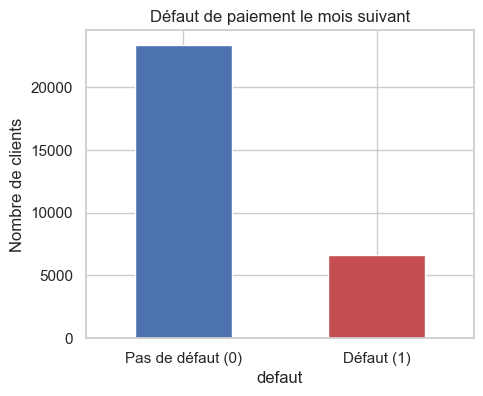

In [6]:
print(df["defaut"].value_counts())

print("Taux de défaut :", round(df["defaut"].mean() * 100, 1), "%")

print("Accuracy si on prédit toujours « pas de défaut » :", round((1 - df["defaut"].mean()) * 100, 1), "%")

# la 22,1 % de défauts, donc l'accuracy n'est pas une bonne métrique

df["defaut"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"], figsize=(5, 4))

plt.xticks([0, 1], ["Pas de défaut (0)", "Défaut (1)"], rotation=0)

plt.ylabel("Nombre de clients")

plt.title("Défaut de paiement le mois suivant")

plt.savefig(FIGURES + "Cible.png", dpi=150, bbox_inches="tight")

plt.show()

6 636 clients sur 30 000 sont en défaut, soit 22,1 %. Un modèle qui répond toujours « pas de défaut » aurait 77,9 % d'accuracy sans trouver un seul défaut. Je ferai donc un split stratifié, et je n'utiliserai pas l'accuracy pour choisir le modèle.

## 6. La règle actuelle

Je calcule ce que donne la règle de référence : appeler les clients déjà en retard en septembre. Je regarde le nombre de défauts trouvés, mais aussi les montants, parce qu'un défaut sur une grosse facture coûte plus cher.

In [7]:
regle = df["retard_sep"] >= 1            

defaut = df["defaut"] == 1

montant = df["facture_sep"].clip(lower=0) 

# la regle actuelle est d' appeler les clients en retard en septembre 

print("Clients appelés :", round(regle.mean() * 100, 1), "%")

print("Défauts trouvés (rappel) :", round((regle & defaut).sum() / defaut.sum() * 100, 1), "%")

print("Appels utiles (précision) :", round((regle & defaut).sum() / regle.sum() * 100, 1), "%")

print("Montants en défaut couverts :", round(montant[regle & defaut].sum() / montant[defaut].sum() * 100, 1), "%")

Clients appelés : 22.7 %
Défauts trouvés (rappel) : 51.7 %
Appels utiles (précision) : 50.3 %
Montants en défaut couverts : 54.6 %


La règle appelle 22,7 % des clients et trouve 51,7 % des défauts. Un appel sur deux est utile (précision de 50,3 %). Mais elle ne couvre que 54,6 % des montants en défaut, parce qu'elle ne regarde pas le montant de la facture. C'est la référence que le modèle doit battre. Je referai ce calcul sur le jeu de test dans les notebooks 02 et 03.

## 7. Liens avec la cible

La fonction ci-dessous affiche le taux de défaut par groupe. La ligne rouge est la moyenne (22 %).

In [8]:
def graphique_taux(groupes, titre, ax, noms=None):
    
    """Barres du taux de défaut (%) par groupe, avec la moyenne en rouge."""
    
    taux = df.groupby(groupes, observed=True)["defaut"].mean() * 100
    
    if noms is not None:
        taux = taux.rename(index=noms)  
#une fonction qui trace le taux de défaut par groupe avec la moyenne en rouge
        
    ax.bar([str(g) for g in taux.index], taux.values, color="#4C72B0")
    
    ax.axhline(df["defaut"].mean() * 100, color="red", linestyle="--", label="moyenne (22 %)")
    
    ax.set_ylim(0, taux.max() * 1.25)              
    
    ax.set_title(titre)
    
    ax.set_ylabel("Taux de défaut (%)")
    
    ax.legend(loc="upper left")
    
    return taux.round(1)

### 7.1 Retard en septembre et plafond

retard_sep
non utilisée    13.2
payé            16.8
partiel         12.8
1 mois          33.9
2 mois          69.1
3 mois et +     71.9
Name: defaut, dtype: float64
plafond_credit
≤ 50 k       31.8
50-100 k     25.8
100-180 k    19.9
180-270 k    16.9
> 270 k      13.8
Name: defaut, dtype: float64


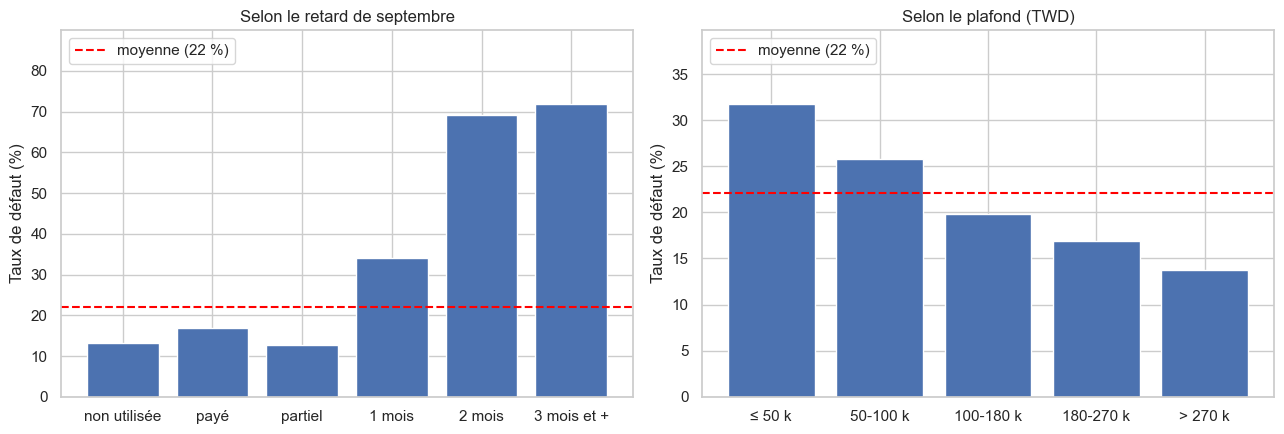

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#taux de défaut selon le retard de septembre et selon le plafond aussi

noms_retard = {-2: "non utilisée", -1: "payé", 0: "partiel", 1: "1 mois", 2: "2 mois", 3: "3 mois et +"}

print(graphique_taux(df["retard_sep"].clip(upper=3), "Selon le retard de septembre", axes[0], noms_retard))

plafond = pd.qcut(df["plafond_credit"], 5, labels=["≤ 50 k", "50-100 k", "100-180 k", "180-270 k", "> 270 k"])

print(graphique_taux(plafond, "Selon le plafond (TWD)", axes[1]))

plt.tight_layout()

plt.savefig(FIGURES + "retard plafond.png", dpi=150, bbox_inches="tight")

plt.show()

- Le retard de septembre est le signal le plus fort. Sans retard, le taux de défaut est entre 13 et 17 %. Il monte à 34 % avec un mois de retard, et à environ 70 % à partir de deux mois.
- Plus le plafond est bas, plus le taux de défaut est élevé : 32 % pour les plafonds de 50 000 TWD ou moins, 14 % au-dessus de 270 000 TWD.

### 7.2 Corrélations

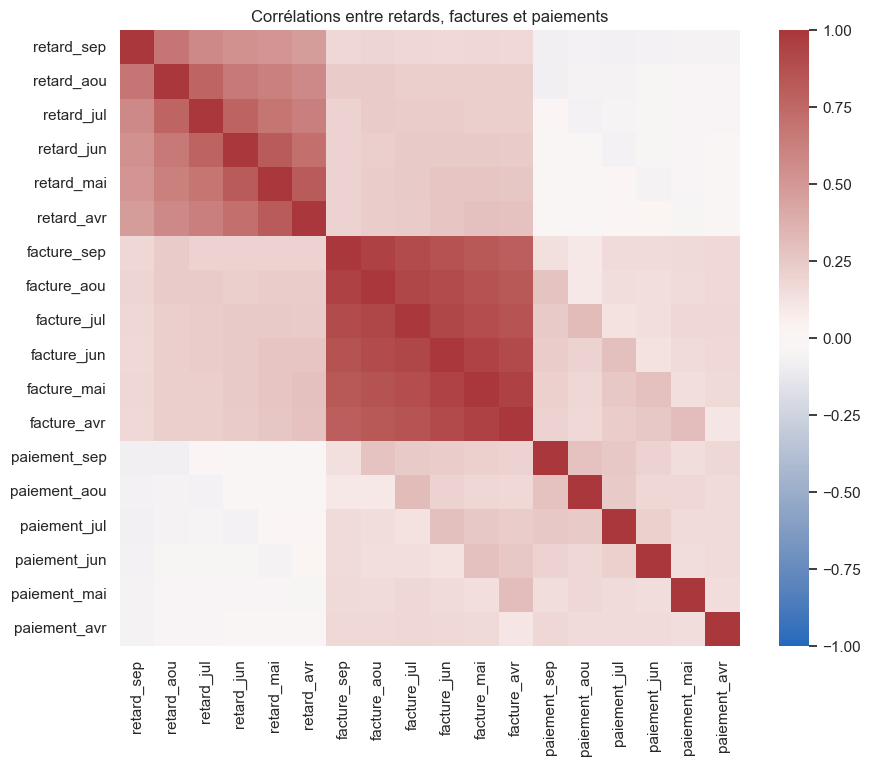

Corrélation avec la cible :
retard_sep    0.325
retard_aou    0.264
retard_jul    0.235
retard_jun    0.217
retard_mai    0.204
retard_avr    0.187
education     0.034
age           0.014
dtype: float64


In [10]:
plt.figure(figsize=(10, 8))

sns.heatmap(df[RETARDS + FACTURES + PAIEMENTS].corr(), cmap="vlag", center=0, vmin=-1, vmax=1)

plt.title("Corrélations entre retards, factures et paiements")

plt.savefig(FIGURES + "Correlation.png", dpi=150, bbox_inches="tight")

plt.show()

#correlations entre retards, factures et paiements, puis avec la cible

print("Corrélation avec la cible :")

print(df.drop(columns=["id_client", "defaut"]).corrwith(df["defaut"]).sort_values(ascending=False).round(3).head(8))

Les factures des 6 mois sont très corrélées entre elles (0,80 à 0,95). Les retards aussi (0,47 à 0,82). Il y a donc beaucoup d'information en double. Les variables les plus corrélées avec le défaut sont les retards, surtout les plus récents.

### 7.3 Sexe, âge, situation familiale, études

Je n'utiliserai pas le sexe, l'âge et la situation familiale dans le modèle. Je les regarde quand même, pour vérifier plus tard que le modèle ne désavantage pas un groupe (axe 9).

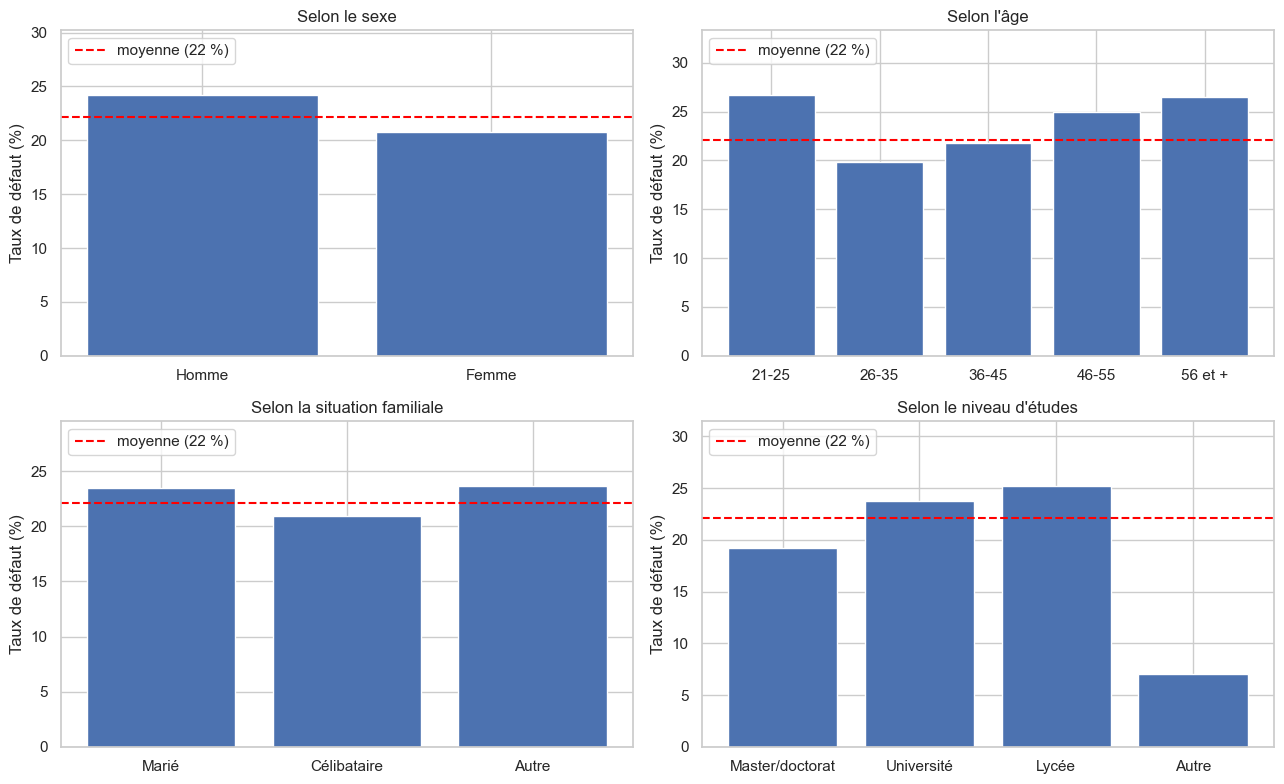

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

#sexe, âge, situation, études : regardés pour l'équité, pas utilisés dans le modèle 

graphique_taux(df["sexe"], "Selon le sexe", axes[0, 0], {1: "Homme", 2: "Femme"})

age = pd.cut(df["age"], [20, 25, 35, 45, 55, 80], labels=["21-25", "26-35", "36-45", "46-55", "56 et +"])

graphique_taux(age, "Selon l'âge", axes[0, 1])

graphique_taux(df["statut_marital"], "Selon la situation familiale", axes[1, 0],
               {1: "Marié", 2: "Célibataire", 3: "Autre"})

graphique_taux(df["education"], "Selon le niveau d'études", axes[1, 1],
               {1: "Master/doctorat", 2: "Université", 3: "Lycée", 4: "Autre"})

plt.tight_layout()

plt.savefig(FIGURES + "criteres proteges.png", dpi=150, bbox_inches="tight")

plt.show()

- Hommes : 24 % de défauts, femmes : 21 %.
- Âge : 27 % chez les 21-25 ans et chez les 56 ans et plus, 20 % chez les 26-35 ans.
- Situation familiale : peu de différence (entre 21 et 24 %).
- Études : 19 % pour master/doctorat, 24 % pour université, 25 % pour lycée. Le groupe « autre » (7 %) est petit (468 clients).

Pour `education`, je déciderai au notebook 02 si je la garde, en regardant ce qu'elle apporte au modèle.

## 8. Audit de fuite de données

Pour chaque variable, je vérifie qu'elle est connue au moment de la décision, c'est-à-dire après le relevé de septembre et avant le paiement suivant.

| Variable | Connue au moment de la décision ? | Utilisée ? |
|---|---|---|
| `id_client` | oui | non, c'est un identifiant |
| `defaut` | non | non, c'est la cible |
| retards, factures, paiements (avril à septembre) | oui | oui |
| `plafond_credit` | oui | oui |
| `education` | oui | à décider (notebook 02) |
| `sexe`, `age`, `statut_marital` | oui | non, pour ne pas discriminer |

Il n'y a pas de variable connue seulement après le défaut (montant recouvré, date du défaut, etc.). Deux limites :
- la documentation ne précise pas exactement le mois de la cible, je suppose que c'est octobre 2005 ;
- tous les clients sont observés sur la même période. Un split aléatoire ne crée donc pas de fuite, mais je ne peux pas tester le modèle sur un autre mois.

## 9. Nouvelles variables

J'ai créé trois variables (fonction `ajouter_variables()` dans `src/donnees.py`) :
1. `nb_mois_retard` : nombre de mois en retard sur les 6 derniers mois. Un retard isolé n'est pas pareil que des retards répétés.
2. `taux_utilisation` : facture de septembre divisée par le plafond. Ça mesure à quel point le client utilise sa carte jusqu'à la limite.
3. `taux_remboursement` : paiement de septembre divisé par la facture d'août, limité entre 0 et 1 (1 si la facture était nulle ou négative). Ça mesure quelle part de sa facture le client rembourse.

       nb_mois_retard  taux_utilisation  taux_remboursement
count        30000.00          30000.00            30000.00
mean             0.83              0.42                0.40
std              1.55              0.41                0.44
min              0.00             -0.62                0.00
25%              0.00              0.02                0.04
50%              0.00              0.31                0.10
75%              1.00              0.83                1.00
max              6.00              6.46                1.00

Corrélation avec la cible :
nb_mois_retard        0.398
retard_sep            0.325
taux_utilisation      0.086
taux_remboursement   -0.104
dtype: float64


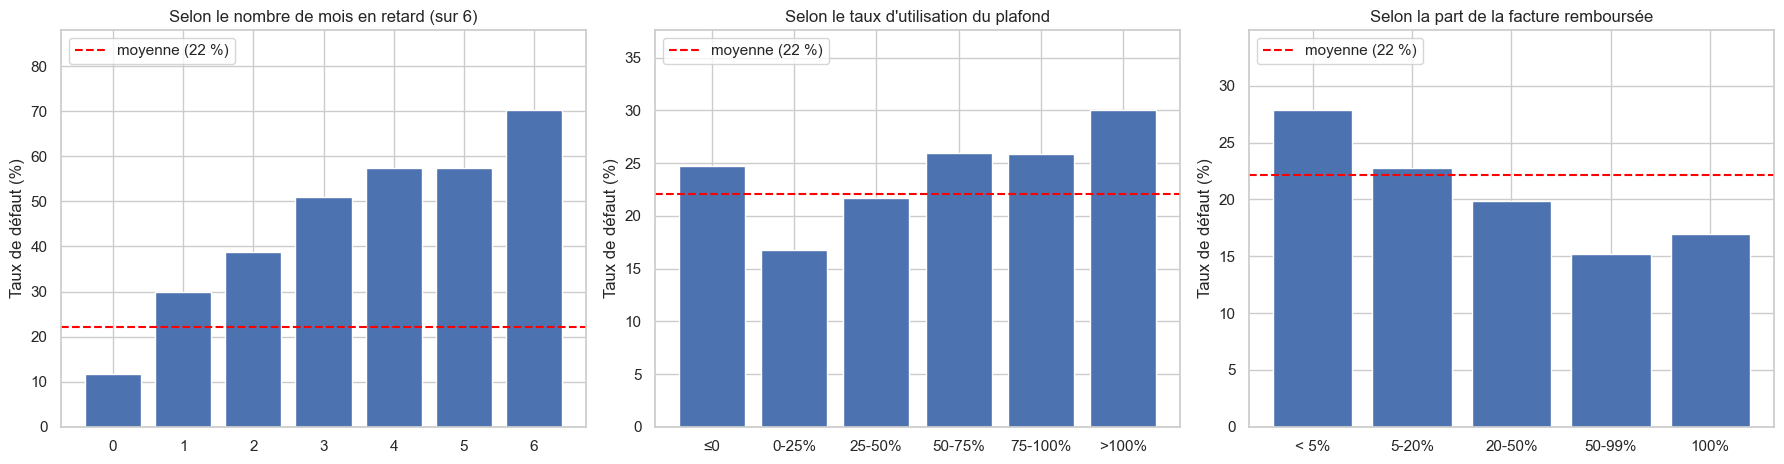

In [12]:
df = ajouter_variables(df)

print(df[["nb_mois_retard", "taux_utilisation", "taux_remboursement"]].describe().round(2))

print()

print("Corrélation avec la cible :")

print(df[["nb_mois_retard", "retard_sep", "taux_utilisation", "taux_remboursement"]].corrwith(df["defaut"]).round(3))

# les valeurs contruites et le lien entre les 3 et le defaut

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

graphique_taux(df["nb_mois_retard"], "Selon le nombre de mois en retard (sur 6)", axes[0])

utilisation = pd.cut(df["taux_utilisation"], [-np.inf, 0, 0.25, 0.5, 0.75, 1, np.inf],
                     labels=["≤0", "0-25%", "25-50%", "50-75%", "75-100%", ">100%"])

graphique_taux(utilisation, "Selon le taux d'utilisation du plafond", axes[1])

remboursement = pd.cut(df["taux_remboursement"], [-0.01, 0.05, 0.2, 0.5, 0.99, 1.0],
                       labels=["< 5%", "5-20%", "20-50%", "50-99%", "100%"])

graphique_taux(remboursement, "Selon la part de la facture remboursée", axes[2])

plt.tight_layout()

plt.savefig(FIGURES + "variables construite.png", dpi=150, bbox_inches="tight")

plt.show() 

- `nb_mois_retard` est la variable la plus corrélée au défaut (0,40, contre 0,32 pour `retard_sep`). Le taux de défaut passe de 12 % pour les clients sans aucun retard à 70 % pour ceux en retard les 6 mois.
- `taux_utilisation` : 17 % de défauts entre 0 et 25 % d'utilisation, 30 % au-dessus du plafond. Les clients avec un solde nul ou négatif ont aussi un taux élevé (25 %), donc la relation n'est pas linéaire.
- `taux_remboursement` : 28 % de défauts pour ceux qui remboursent moins de 5 % de leur facture, 17 % pour ceux qui remboursent tout.

## 10. Résumé

- Données complètes. Codes non documentés regroupés. Valeurs extrêmes et factures négatives gardées.
- 22,1 % de défauts : split stratifié, pas d'accuracy pour choisir le modèle.
- Les retards de paiement sont les variables les plus utiles, puis le plafond.
- Référence à battre : la règle actuelle couvre 54,6 % des montants en défaut en appelant 22,7 % des clients.
- Variables du modèle : plafond, retards, factures, paiements et les 3 nouvelles variables. `education` à décider. Exclues : identifiant, sexe, âge, situation familiale.
- Pour la régression logistique : tester le log des montants, car ils sont très asymétriques et corrélés entre eux.